# NB03 - Analisis dan Evaluasi Hasil Simulasi

Notebook ini menghitung CIEDE2000 antara citra masukan dan hasil simulasi NB02 pada kelompok seleksi confusion line NB01. Laporan NB02 harus mencakup tepat empat severity untuk setiap pasangan citra dan tipe CVD yang dipilih NB01.

Hasil diekspor per citra, kelas buah, kelompok seleksi (`confusion_line_protan` atau `confusion_line_deutan`), dan kondisi simulasi. Kelompok seleksi menggantikan domain Red-Orange/Green-Yellow. Kelas buah dipertahankan sebagai metadata, tanpa menjadi subfolder citra simulasi.

Rata-rata kelompok protan dan deutan dapat berasal dari sampel berbeda. Perbandingan berpasangan tambahan hanya memakai citra yang dipilih untuk kedua tipe CVD pada severity yang sama, dengan verifikasi hash citra asli identik. Irisan tersebut belum tentu seimbang antar kelas.

Delta E dihitung pada seluruh piksel citra, termasuk latar, sesuai evaluasi sebelumnya. Nilai ini menggambarkan perubahan warna akibat simulasi, bukan validasi persepsi manusia atau ukuran langsung kesulitan mengenali buah.


In [1]:
%pip install opencv-python-headless numpy pandas matplotlib scikit-image -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Memuat Laporan Simulasi

In [ ]:
from __future__ import annotations
import sys, time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.color import deltaE_ciede2000
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/02/output/simulation_report.csv")
SIMULATION_REPORT_PATH=RESEARCH_ROOT/"notebooks/02/output/simulation_report.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/03/output"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)

SOURCE_KEY = ["subset", "source_class", "source_file_name"]
SELECTION_KEY = [*SOURCE_KEY, "cvd_family"]
JOB_KEY = [*SELECTION_KEY, "severity"]
simulation_report = pd.read_csv(SIMULATION_REPORT_PATH)
required = {*JOB_KEY, "input_path", "output_path", "input_sha256", "output_sha256", "selection_group", "selection_distance_median", "ambiguity_threshold"}
missing = required - set(simulation_report.columns)
if missing:
    raise ValueError(f"Jalankan NB02 terbaru. Kolom laporan belum lengkap: {sorted(missing)}")
if simulation_report.empty or simulation_report[list(required)].isna().any().any():
    raise ValueError("Laporan NB02 kosong atau memiliki nilai wajib yang kosong.")
if simulation_report.duplicated(JOB_KEY).any():
    raise ValueError("Laporan NB02 memiliki pasangan evaluasi berulang.")
selection_path = RESEARCH_ROOT / "notebooks/01/output/confusion_line_selected_by_cvd.csv"
selection = pd.read_csv(selection_path)
if selection.empty or selection.duplicated(SELECTION_KEY).any():
    raise ValueError("Manifest seleksi NB01 kosong atau memiliki duplikat.")
expected = selection[SELECTION_KEY].merge(pd.DataFrame({"severity": SEVERITIES}), how="cross")
coverage = expected.merge(simulation_report[JOB_KEY], on=JOB_KEY, how="outer", indicator=True, validate="one_to_one")
if not coverage["_merge"].eq("both").all():
    raise ValueError("Laporan NB02 tidak sesuai seleksi NB01 atau severity belum lengkap. Jalankan ulang NB02.")
import json
with (SIMULATION_REPORT_PATH.parent / "simulation_summary.json").open(encoding="utf-8") as file:
    simulation_metadata = json.load(file)
if simulation_metadata.get("selection_manifest_sha256") != sha256_file(selection_path):
    raise ValueError("Manifest NB01 berubah sejak NB02 dijalankan. Jalankan ulang NB02.")
checked = simulation_report.merge(
    selection[[*SELECTION_KEY, "output_sha256"]].rename(columns={"output_sha256": "selected_input_sha256"}),
    on=SELECTION_KEY, validate="many_to_one",
)
if not checked["input_sha256"].eq(checked["selected_input_sha256"]).all():
    raise ValueError("Hash masukan NB02 berbeda dari seleksi NB01.")
if not simulation_report["selection_group"].eq("confusion_line_" + simulation_report["cvd_family"]).all():
    raise ValueError("Kelompok seleksi tidak sesuai tipe CVD.")
simulation_report = simulation_report.sort_values(JOB_KEY).reset_index(drop=True)
source_count = len(simulation_report[SOURCE_KEY].drop_duplicates())
print(f"Pasangan citra yang dievaluasi: {len(simulation_report)}")
print(simulation_report.groupby(["cvd_family", "severity"]).size().to_string())


Pasangan citra yang dievaluasi: 4200
cvd_family  severity
deutan      0.25        525
            0.50        525
            0.75        525
            1.00        525
protan      0.25        525
            0.50        525
            0.75        525
            1.00        525


## Tahap 2 - Menghitung ΔE00 Setiap Pasangan Citra


In [3]:
def mean_delta_e00(input_bgr: np.ndarray, output_bgr: np.ndarray) -> float:
    first=cv2.cvtColor(input_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    second=cv2.cvtColor(output_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    first[:,:,0]*=100.0/255.0; second[:,:,0]*=100.0/255.0
    first[:,:,1:]-=128.0; second[:,:,1:]-=128.0
    return float(deltaE_ciede2000(first,second).mean())

started = time.perf_counter()
evaluation_rows=[]
for index,row in simulation_report.iterrows():
    if sha256_file(Path(row["input_path"])) != row["input_sha256"] or sha256_file(Path(row["output_path"])) != row["output_sha256"]:
        raise ValueError(f"Hash citra berubah sejak NB02: {row['output_path']}")
    original=cv2.imread(row["input_path"],cv2.IMREAD_COLOR)
    simulated=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    if original is None or simulated is None or original.shape != simulated.shape: raise ValueError(f"Pasangan citra tidak valid: {row['output_path']}")
    evaluation_rows.append({
        "subset": row["subset"],
        "source_class": row["source_class"],
        "source_file_name": row["source_file_name"],
        "selection_group": row["selection_group"],
        "selection_distance_median": row["selection_distance_median"],
        "ambiguity_threshold": row["ambiguity_threshold"],
        "input_sha256": row["input_sha256"],
        "cvd_family": row["cvd_family"],
        "severity": row["severity"],
        "input_path": row["input_path"],
        "output_path": row["output_path"],
        "mean_delta_e00": mean_delta_e00(original, simulated)
    })
    if (index+1)%1000==0 or index+1==len(simulation_report): print(f"{index+1}/{len(simulation_report)} pasangan dievaluasi, {time.perf_counter()-started:.1f} detik")
evaluation=pd.DataFrame(evaluation_rows).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
print(f"Rata-rata ΔE00 keseluruhan: {evaluation['mean_delta_e00'].mean():.4f}")


1000/4200 pasangan dievaluasi, 228.0 detik
2000/4200 pasangan dievaluasi, 522.2 detik
3000/4200 pasangan dievaluasi, 827.3 detik
4000/4200 pasangan dievaluasi, 1046.6 detik
4200/4200 pasangan dievaluasi, 1077.1 detik
Rata-rata ΔE00 keseluruhan: 6.7609


In [4]:
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def read_bgr(path: str) -> np.ndarray:
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Citra tidak dapat dibaca: {path}")
    return image


def calculate_delta_e00_map(
    original_bgr: np.ndarray,
    simulated_bgr: np.ndarray,
) -> np.ndarray:
    original_lab = cv2.cvtColor(
        original_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    simulated_lab = cv2.cvtColor(
        simulated_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    original_lab[:, :, 0] *= 100.0 / 255.0
    simulated_lab[:, :, 0] *= 100.0 / 255.0

    original_lab[:, :, 1:] -= 128.0
    simulated_lab[:, :, 1:] -= 128.0

    return deltaE_ciede2000(original_lab, simulated_lab)

In [5]:
def select_examples(group: pd.DataFrame) -> pd.DataFrame:
    cvd_family, severity = group.iloc[0][["cvd_family", "severity"]]

    ordered = group.sort_values(
        ["mean_delta_e00", "source_class", "source_file_name"]
    ).reset_index(drop=True)

    median_value = ordered["mean_delta_e00"].median()

    median_index = (
        (ordered["mean_delta_e00"] - median_value)
        .abs()
        .sort_values(kind="stable")
        .index[0]
    )

    examples = pd.concat(
        [
            ordered.iloc[[0]].assign(example_type="terendah"),
            ordered.loc[[median_index]].assign(
                example_type="mendekati_median"
            ),
            ordered.iloc[[-1]].assign(example_type="tertinggi"),
        ],
        ignore_index=True,
    )

    examples["cvd_family"] = cvd_family
    examples["severity"] = severity

    return examples.drop_duplicates(
        subset=[
            "source_class",
            "source_file_name",
            "cvd_family",
            "severity",
        ]
    )


representative_cases = pd.concat(
    [select_examples(group) for _, group in evaluation.groupby(["cvd_family", "severity"])],
    ignore_index=True,
)

write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"],
)

representative_cases[
    [
        "cvd_family",
        "severity",
        "example_type",
        "selection_group",
        "source_class",
        "source_file_name",
        "mean_delta_e00",
    ]
]


,cvd_family,severity,example_type,selection_group,source_class,source_file_name,mean_delta_e00
0,deutan,0.25,terendah,confusion_line_deutan,006banana,113.png,0.453067
1,deutan,0.25,mendekati_median,confusion_line_deutan,015pomelo,81.png,2.587237
2,deutan,0.25,tertinggi,confusion_line_deutan,002orange,204.png,9.924043
3,deutan,0.50,terendah,confusion_line_deutan,006banana,113.png,0.715256
4,deutan,0.50,mendekati_median,confusion_line_deutan,015pomelo,74.png,4.306539
5,deutan,0.50,tertinggi,confusion_line_deutan,002orange,204.png,18.116657
6,deutan,0.75,terendah,confusion_line_deutan,006banana,113.png,0.925051
7,deutan,0.75,mendekati_median,confusion_line_deutan,015pomelo,74.png,5.514713
8,deutan,0.75,tertinggi,confusion_line_deutan,001apple,87.png,25.832016
9,deutan,1.00,terendah,confusion_line_deutan,006banana,113.png,1.253533


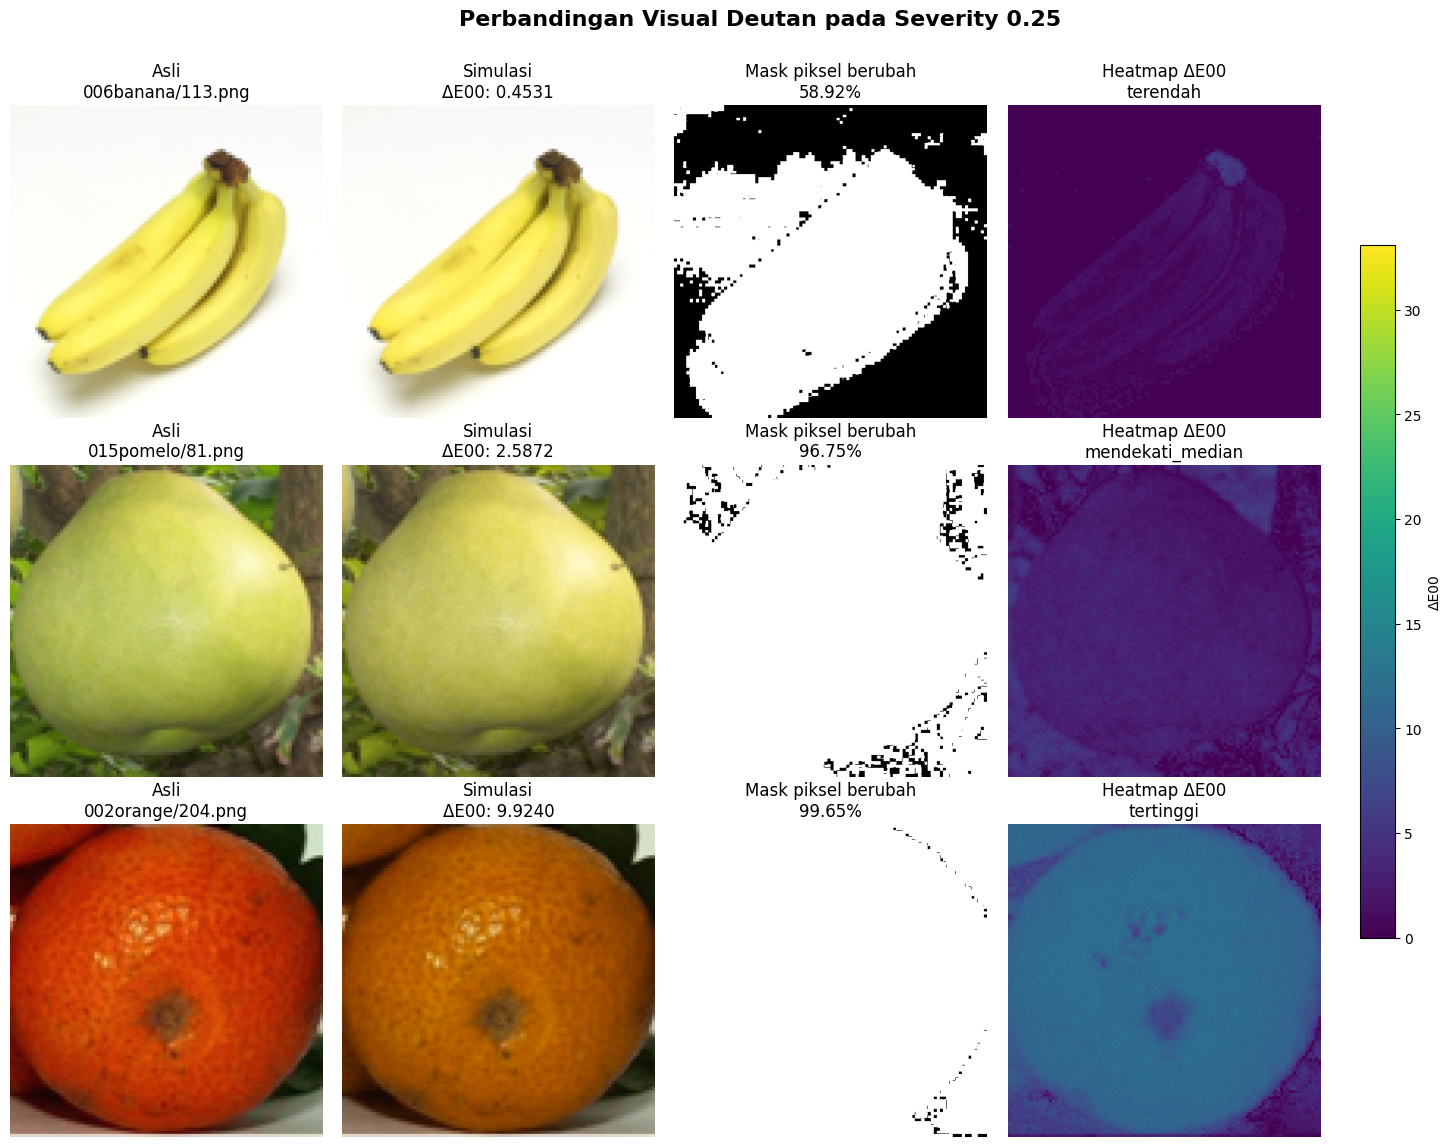

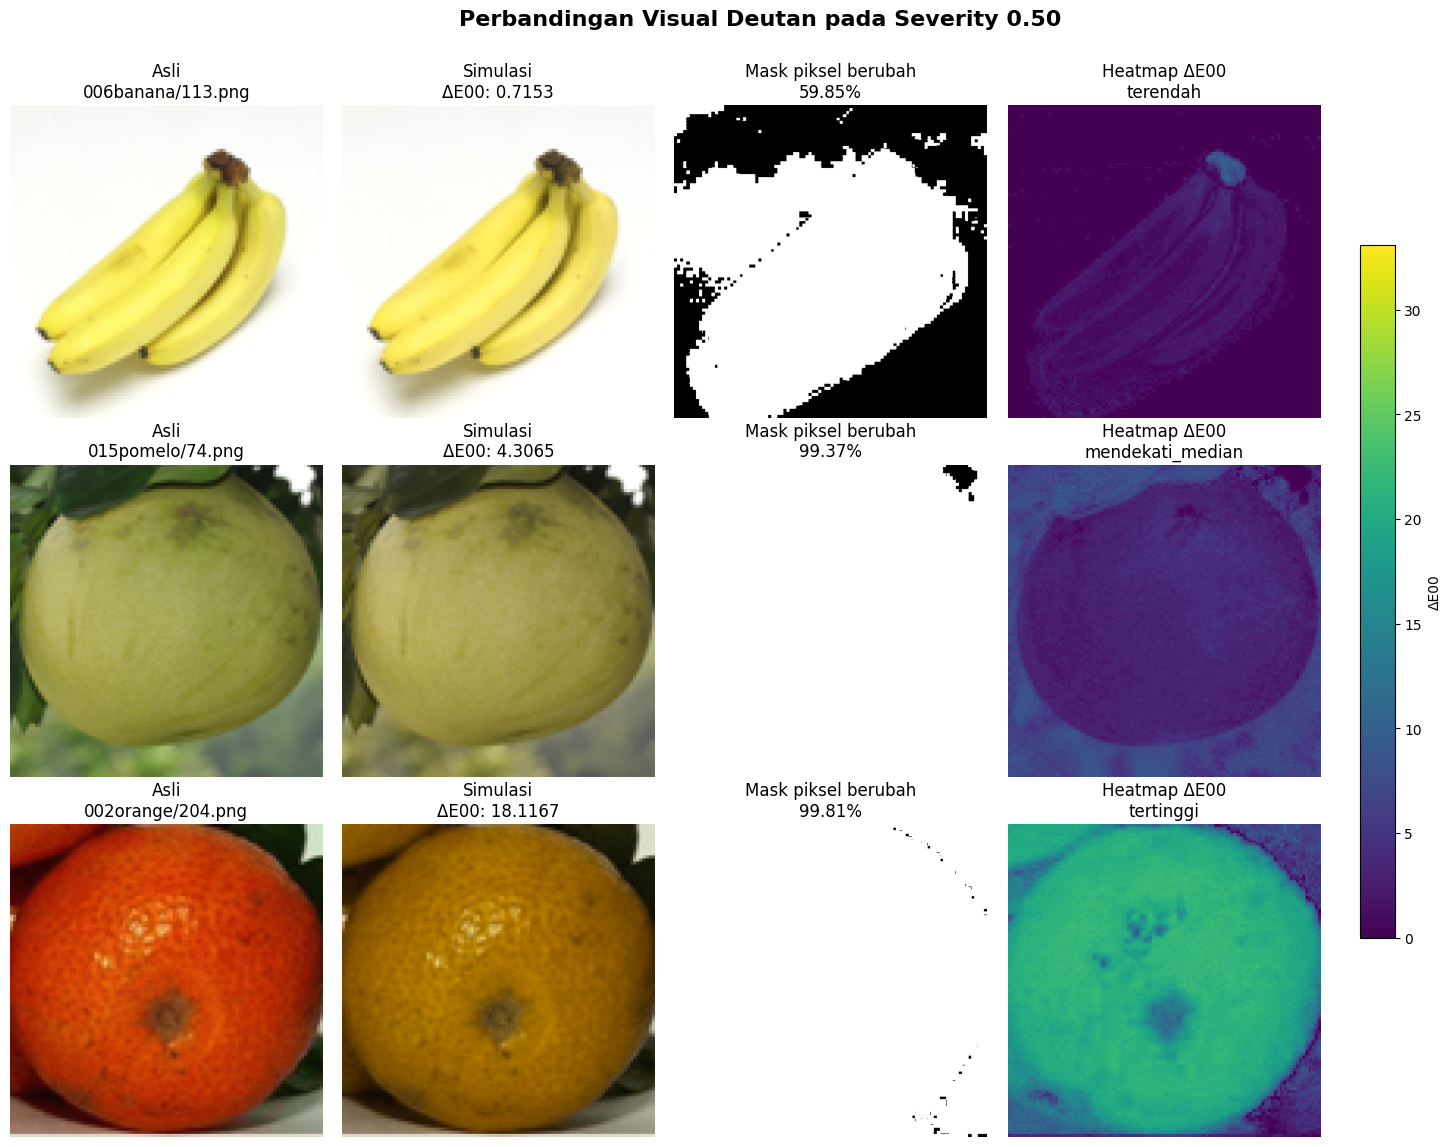

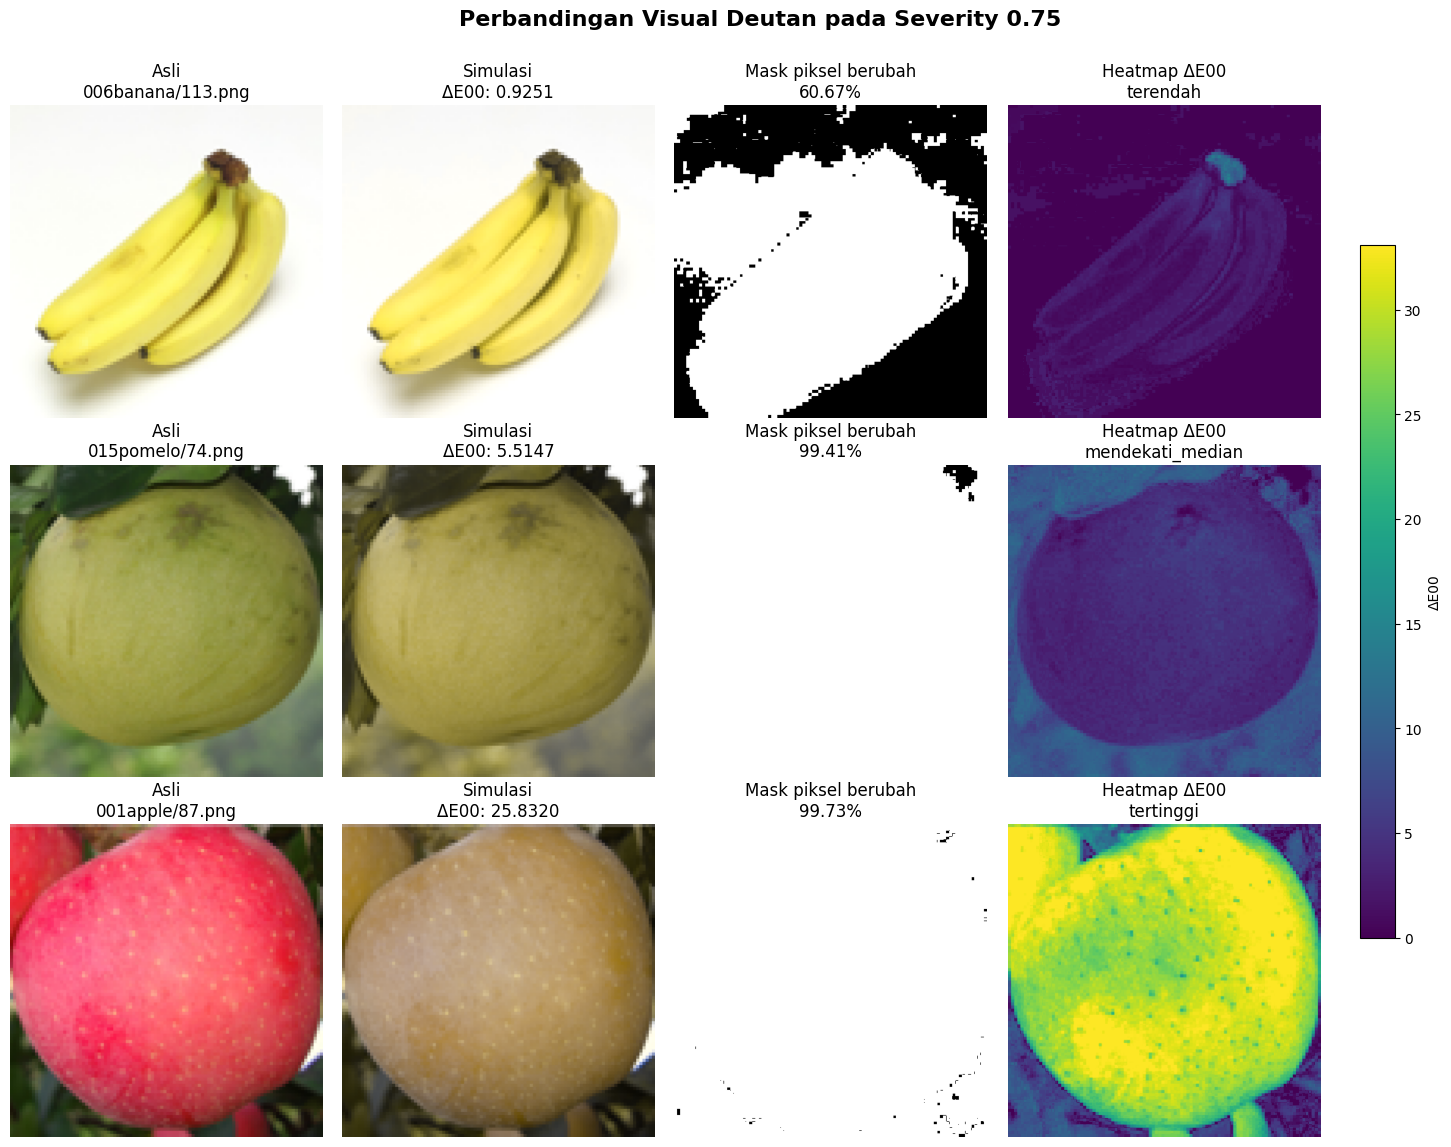

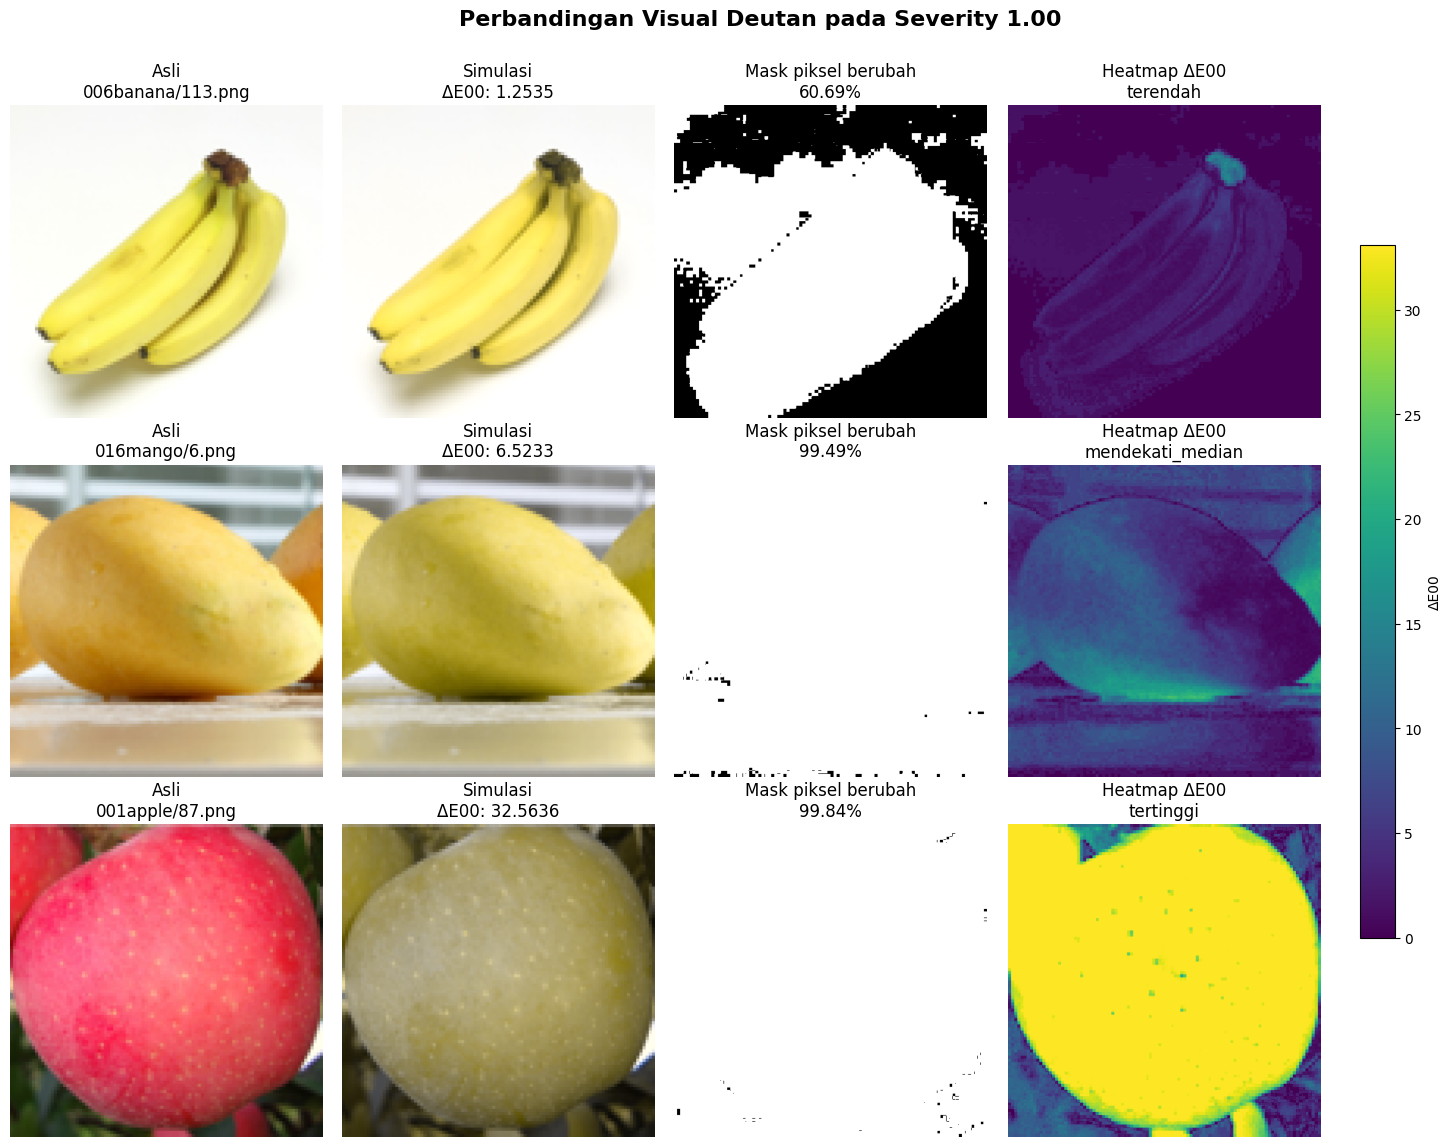

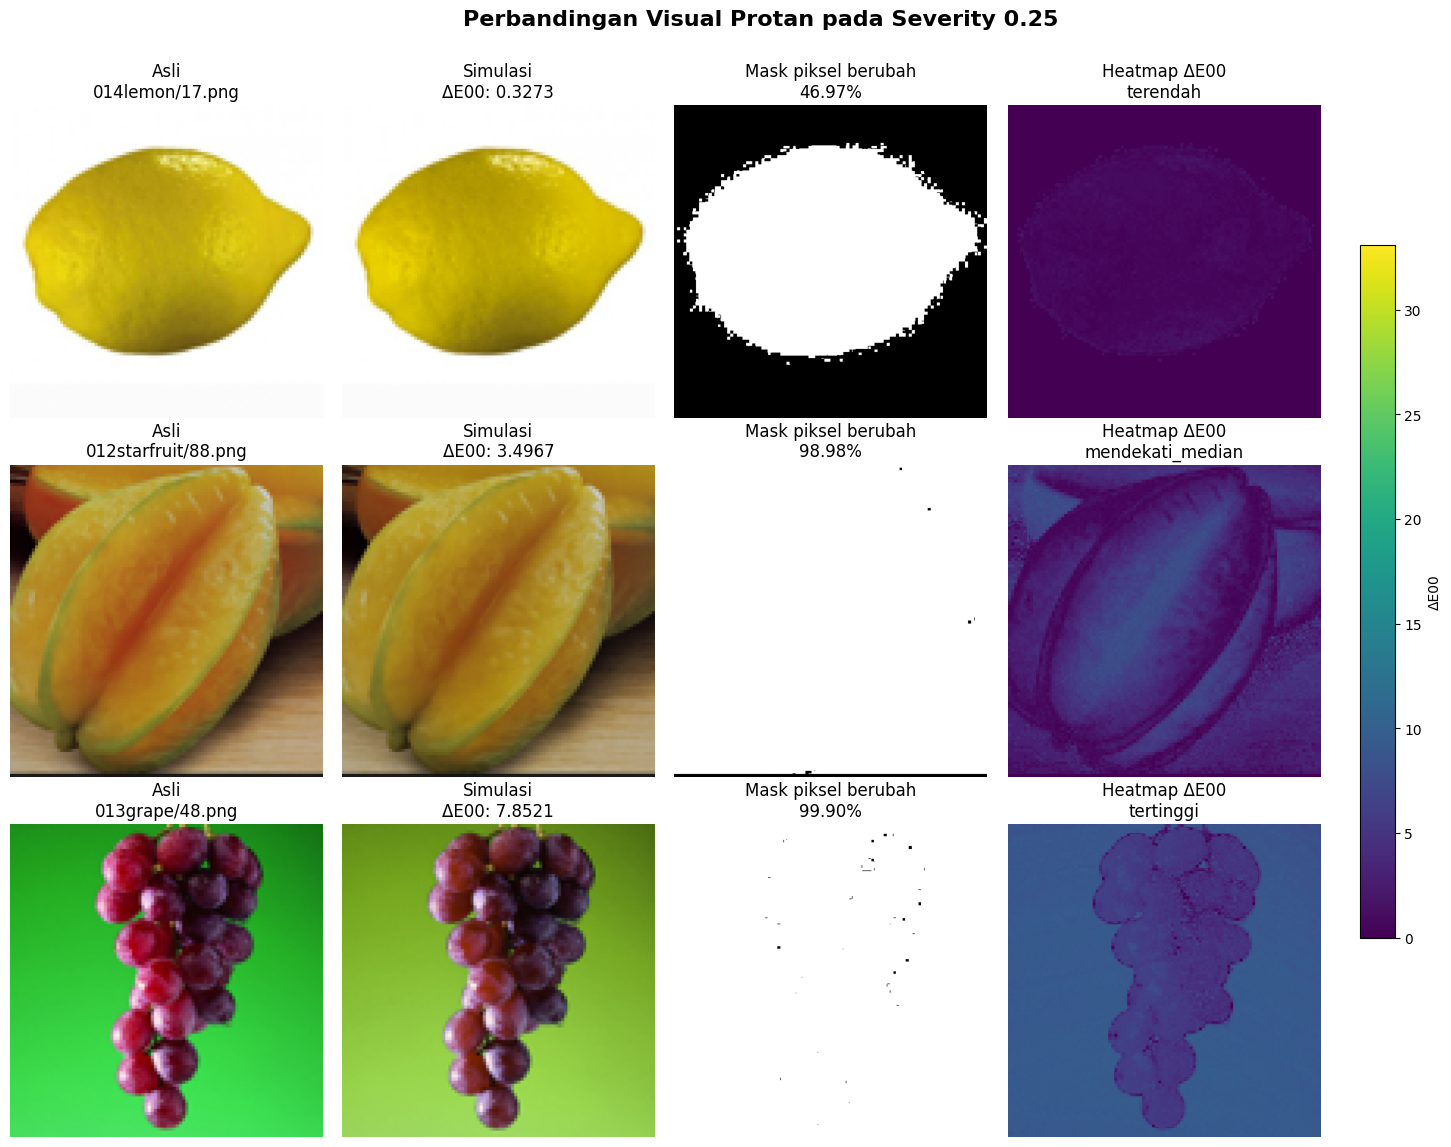

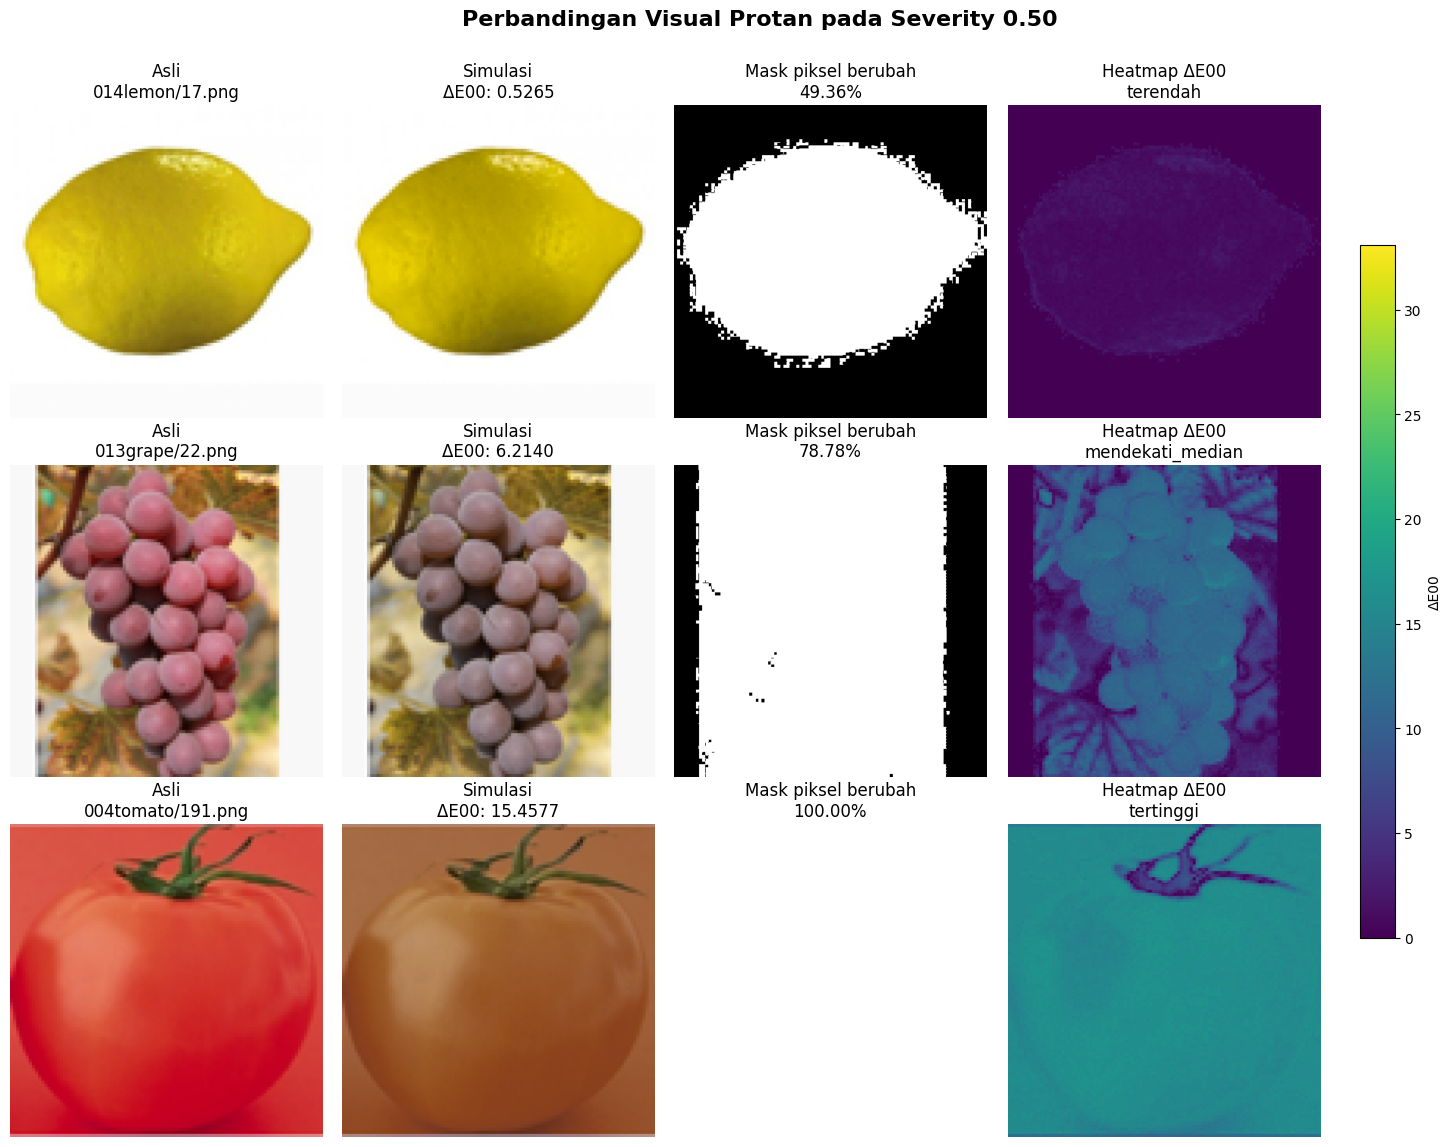

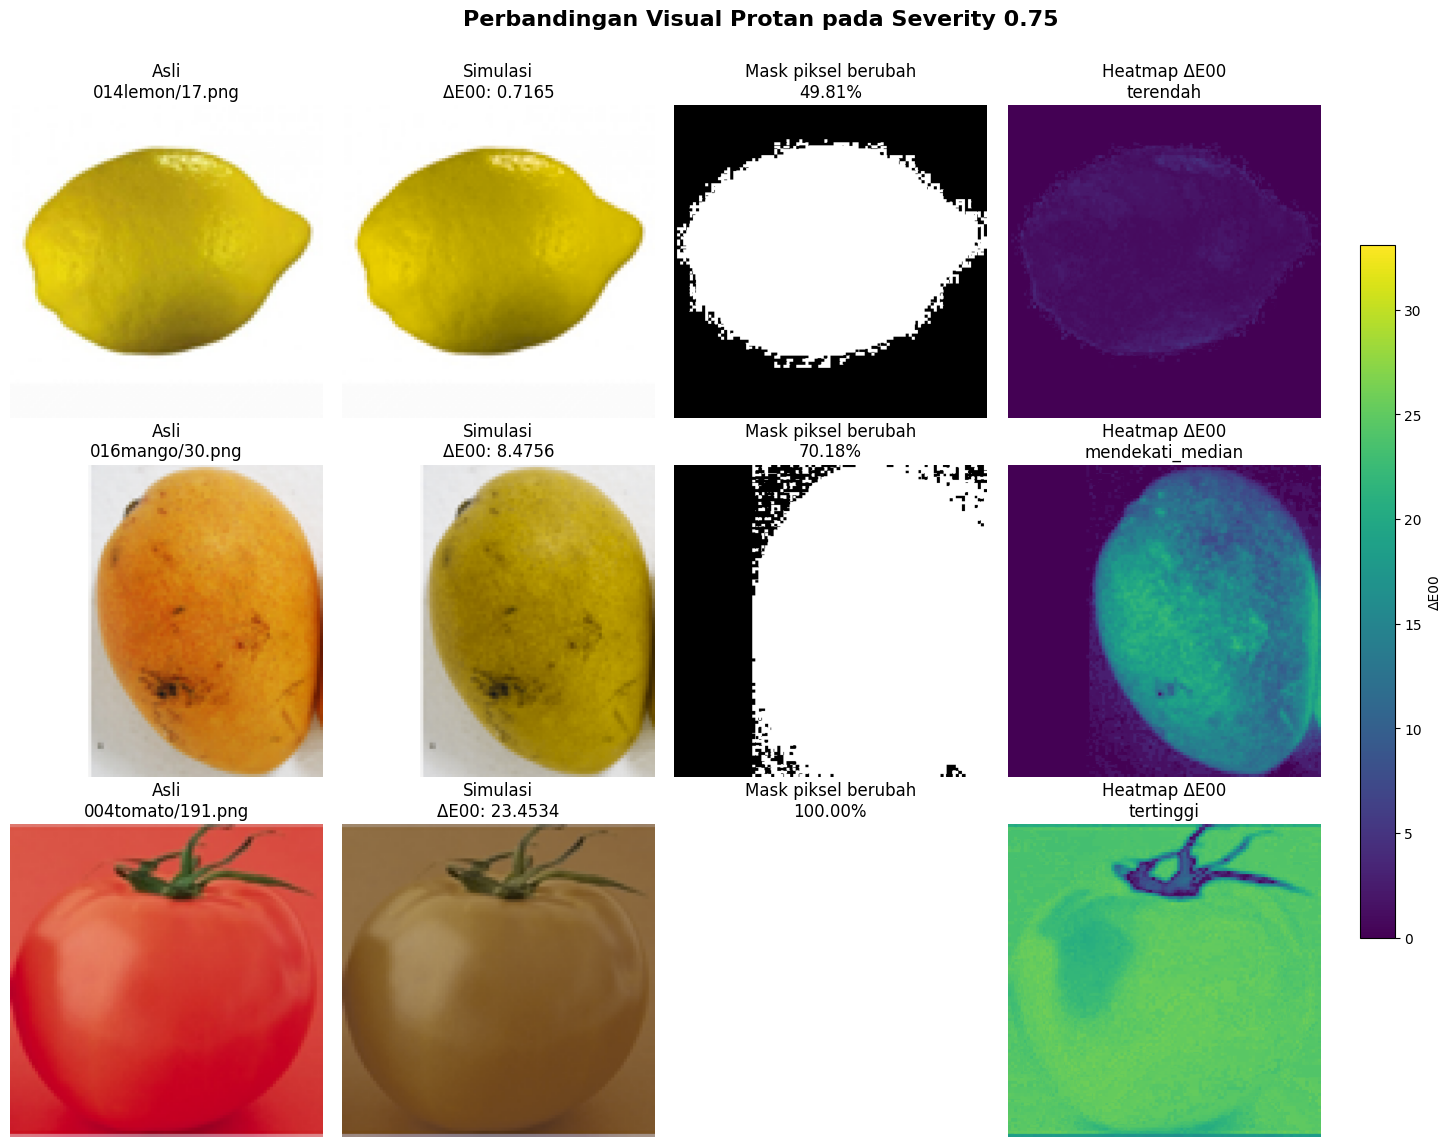

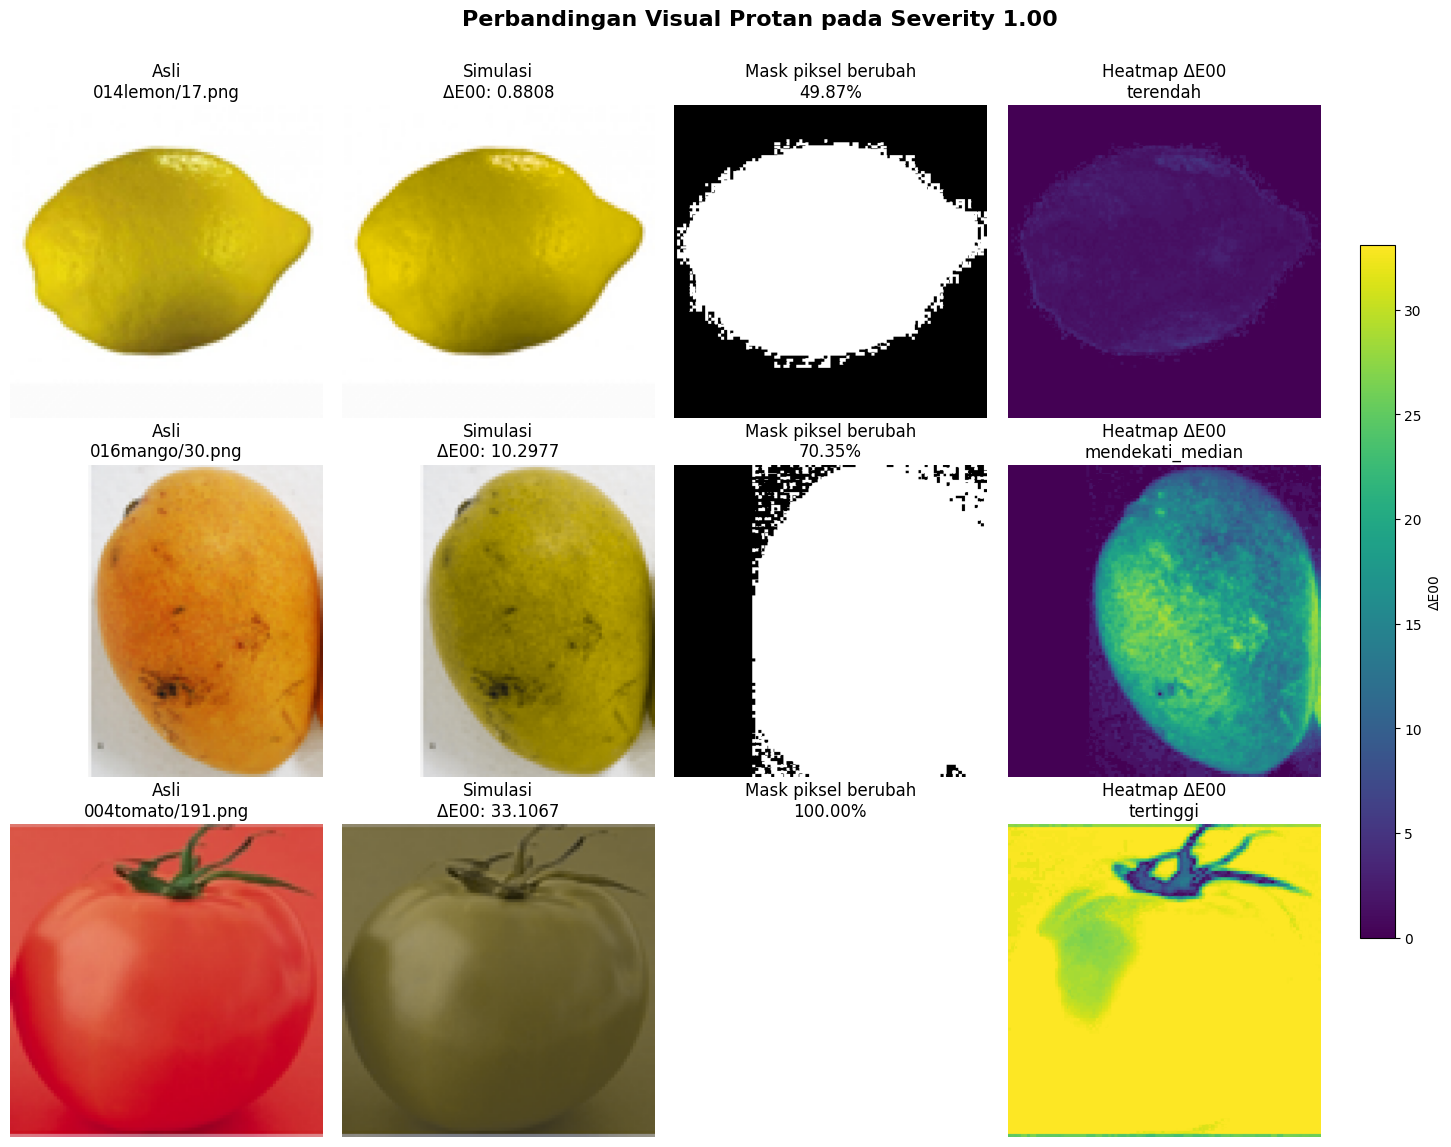

In [6]:
delta_e00_max = float(evaluation["mean_delta_e00"].max())

example_order = {
    "terendah": 0,
    "mendekati_median": 1,
    "tertinggi": 2,
}


def create_visual_panel(cases: pd.DataFrame) -> None:
    ordered_cases = cases.sort_values(
        "example_type",
        key=lambda values: values.map(example_order),
    )

    figure, axes = plt.subplots(len(ordered_cases), 4, figsize=(16, 4 * len(ordered_cases)), squeeze=False)

    for row_index, (_, item) in enumerate(ordered_cases.iterrows()):
        original_bgr = read_bgr(item["input_path"])
        simulated_bgr = read_bgr(item["output_path"])

        delta_e00_map = calculate_delta_e00_map(
            original_bgr,
            simulated_bgr,
        )

        changed_mask = np.any(
            original_bgr != simulated_bgr,
            axis=2,
        )

        axes[row_index, 0].imshow(
            cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 0].set_title(
            f"Asli\n{item['source_class']}/{item['source_file_name']}"
        )

        axes[row_index, 1].imshow(
            cv2.cvtColor(simulated_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 1].set_title(
            f"Simulasi\nΔE00: {item['mean_delta_e00']:.4f}"
        )

        axes[row_index, 2].imshow(
            changed_mask,
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_index, 2].set_title(
            f"Mask piksel berubah\n{changed_mask.mean():.2%}"
        )

        heatmap = axes[row_index, 3].imshow(
            delta_e00_map,
            cmap="viridis",
            vmin=0,
            vmax=delta_e00_max,
        )
        axes[row_index, 3].set_title(
            f"Heatmap ΔE00\n{item['example_type']}"
        )

        for axis in axes[row_index]:
            axis.axis("off")

    figure.colorbar(
        heatmap,
        ax=axes[:, 3],
        shrink=0.75,
        label="ΔE00",
    )

    cvd_family = ordered_cases.iloc[0]["cvd_family"]
    severity = ordered_cases.iloc[0]["severity"]

    figure.suptitle(
        f"Perbandingan Visual {cvd_family.title()} "
        f"pada Severity {severity:.2f}",
        fontsize=16,
        fontweight="bold",
    )

    figure.subplots_adjust(
        top=0.90,
        bottom=0.04,
        left=0.03,
        right=0.85,
        hspace=0.15,
        wspace=0.05,
    )

    output_path = (
        FIGURE_DIR
        / f"visual_{cvd_family}_severity_{int(severity * 100):03d}.png"
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)


for _, cases in representative_cases.groupby(
    ["cvd_family", "severity"],
):
    create_visual_panel(cases)


## Tahap 3 - Agregasi Metrik 4 Level, Visualisasi, dan Ekspor Hasil Bab 5


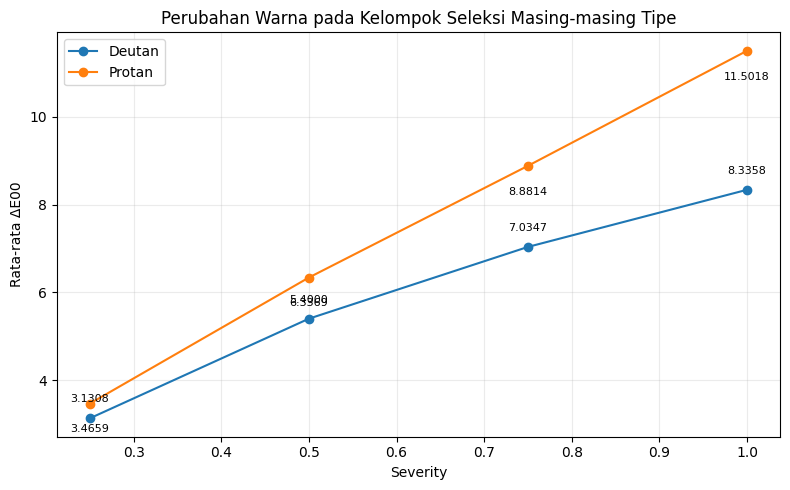

,cvd_family,severity,image_count,mean_delta_e00,std_delta_e00,median_delta_e00,minimum_delta_e00,maximum_delta_e00
0,deutan,0.25,525,3.130794,1.971578,2.587237,0.453067,9.924043
1,deutan,0.50,525,5.400010,3.636422,4.306539,0.715256,18.116657
2,deutan,0.75,525,7.034714,4.964608,5.514713,0.925051,25.832016
3,deutan,1.00,525,8.335822,5.977513,6.523270,1.253533,32.563604
4,protan,0.25,525,3.465911,1.712371,3.496654,0.327324,7.852069
5,protan,0.50,525,6.336940,3.368225,6.213975,0.526466,15.457719
6,protan,0.75,525,8.881423,5.048127,8.475614,0.716454,23.453378
7,protan,1.00,525,11.501751,7.048180,10.297724,0.880818,33.106662


In [7]:
# ==============================================================================
# PERHITUNGAN METRIK 4 LEVEL UNTUK KELENGKAPAN TABEL BAB 5
# ==============================================================================

# Level 1: Per Individu (Tiap Pasangan Citra Asli vs Simulasi)
write_csv(
    evaluation,
    OUTPUT_DIR / "evaluation_individual.csv",
    ["cvd_family", "severity", "source_class", "source_file_name"]
)
write_csv(
    evaluation,
    OUTPUT_DIR / "simulation_evaluation.csv",
    ["cvd_family", "severity", "source_class", "source_file_name"]
)

# Level 2: Per Kelas Buah (mean, std, median, min, max)
class_summary = evaluation.groupby(
    ["cvd_family", "severity", "selection_group", "source_class"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    class_summary,
    OUTPUT_DIR / "evaluation_class_summary.csv",
    ["cvd_family", "severity", "selection_group", "source_class"]
)

# Level 3: Per Kelompok Seleksi (mean, std, median, min, max)
selection_summary = evaluation.groupby(
    ["cvd_family", "severity", "selection_group"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    selection_summary,
    OUTPUT_DIR / "evaluation_selection_summary.csv",
    ["cvd_family", "severity", "selection_group"]
)

# Level 4: Global / Keseluruhan Kondisi (mean, std, median, min, max)
group_summary = evaluation.groupby(
    ["cvd_family", "severity"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_group_summary.csv",
    ["cvd_family", "severity"]
)
write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_global_summary.csv",
    ["cvd_family", "severity"]
)

# Ekspor Kasus Representatif (Terendah, Median, Tertinggi)
write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"]
)

# Ekspor Ringkasan JSON
write_json({
    "total_evaluations": len(evaluation),
    "global_mean_delta_e00": float(evaluation["mean_delta_e00"].mean()),
    "global_std_delta_e00": float(evaluation["mean_delta_e00"].std()) if len(evaluation) > 1 else None,
    "metric_region": "whole_image_including_background",
    "selection_manifest_sha256": sha256_file(selection_path),
    "comparison_scope": "Different selected cohorts; paired comparison is exported separately",
    "global_min_delta_e00": float(evaluation["mean_delta_e00"].min()),
    "global_max_delta_e00": float(evaluation["mean_delta_e00"].max()),
    "levels_exported": [
        "Level 1: evaluation_individual.csv (per individu)",
        "Level 2: evaluation_class_summary.csv (per kelas)",
        "Level 3: evaluation_selection_summary.csv (per kelompok seleksi)",
        "Level 4: evaluation_group_summary.csv / evaluation_global_summary.csv (global)"
    ]
}, OUTPUT_DIR / "evaluation_summary.json")

# Visualisasi Kurva Severity vs Mean Delta E00
plt.figure(figsize=(8, 5))
for family, group in group_summary.groupby("cvd_family"):
    group = group.sort_values("severity")
    line, = plt.plot(
        group["severity"],
        group["mean_delta_e00"],
        marker="o",
        label=family.title()
    )
    if family.lower() == "protan":
        offset = (0, -15)
        va = "top"
    elif family.lower() == "deutan":
        offset = (0, 10)
        va = "bottom"
    else:
        offset = (0, 10)
        va = "bottom"

    for x, y in zip(group["severity"], group["mean_delta_e00"]):
        plt.annotate(
            f"{y:.4f}",
            (x, y),
            textcoords="offset points",
            xytext=offset,
            ha="center",
            va=va,
            fontsize=8
        )

plt.xlabel("Severity")
plt.ylabel("Rata-rata ΔE00")
plt.title("Perubahan Warna pada Kelompok Seleksi Masing-masing Tipe")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mean_delta_e00_by_condition.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

group_summary


## Tahap 4 - Perbandingan Berpasangan pada Irisan Citra

Hanya citra dengan identitas dan hash masukan yang sama pada protan dan deutan dibandingkan. Selisih dihitung sebagai Delta E00 deutan dikurangi protan pada severity yang sama. Nilai positif berarti perubahan warna akibat simulasi deutan lebih besar untuk citra tersebut. Ini analisis deskriptif perubahan warna, tanpa klaim validasi persepsi. Jika tidak ada irisan, CSV tetap diekspor dengan header dan grafik dilewati.


Citra unik pada irisan kedua kelompok: 101


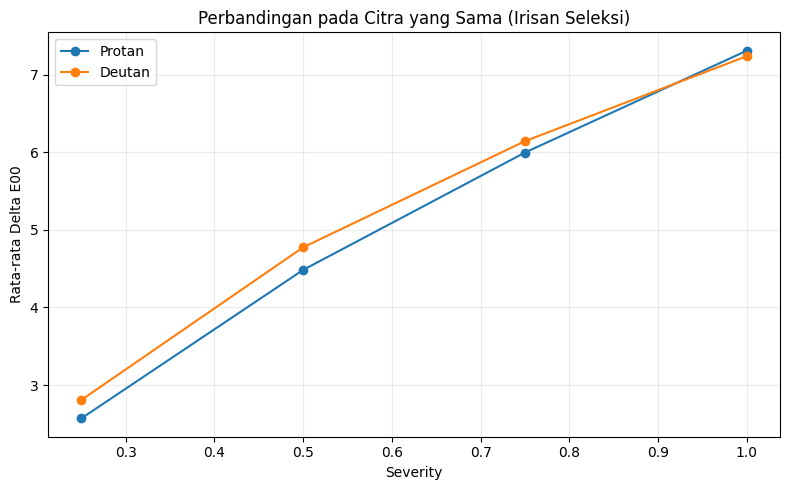

,severity,paired_image_count,mean_protan_delta_e00,mean_deutan_delta_e00,mean_deutan_minus_protan,median_deutan_minus_protan
0,0.25,101,2.570657,2.807820,0.237163,0.104606
1,0.50,101,4.483406,4.774466,0.291059,0.138020
2,0.75,101,5.995251,6.141771,0.146520,0.030778
3,1.00,101,7.307322,7.237097,-0.070225,-0.036546


In [8]:
pair_key = [*SOURCE_KEY, "severity"]
paired_columns = [*pair_key, "input_sha256", "mean_delta_e00"]
protan = evaluation.loc[evaluation["cvd_family"].eq("protan"), paired_columns]
deutan = evaluation.loc[evaluation["cvd_family"].eq("deutan"), paired_columns]
paired = protan.merge(deutan, on=pair_key, suffixes=("_protan", "_deutan"), validate="one_to_one")
if not paired["input_sha256_protan"].eq(paired["input_sha256_deutan"]).all():
    raise ValueError("Citra beridentitas sama memiliki isi berbeda pada kedua kelompok.")
paired["deutan_minus_protan_delta_e00"] = paired["mean_delta_e00_deutan"] - paired["mean_delta_e00_protan"]
write_csv(paired, OUTPUT_DIR / "evaluation_paired_images.csv", pair_key, allow_empty=True)
paired_summary = paired.groupby("severity", as_index=False).agg(
    paired_image_count=("deutan_minus_protan_delta_e00", "size"),
    mean_protan_delta_e00=("mean_delta_e00_protan", "mean"),
    mean_deutan_delta_e00=("mean_delta_e00_deutan", "mean"),
    mean_deutan_minus_protan=("deutan_minus_protan_delta_e00", "mean"),
    median_deutan_minus_protan=("deutan_minus_protan_delta_e00", "median"),
)
write_csv(paired_summary, OUTPUT_DIR / "evaluation_paired_summary.csv", ["severity"], allow_empty=True)
print(f"Citra unik pada irisan kedua kelompok: {len(paired[SOURCE_KEY].drop_duplicates())}")
if not paired.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    for family in CVD_FAMILIES:
        ax.plot(paired_summary["severity"], paired_summary[f"mean_{family}_delta_e00"], marker="o", label=family.title())
    ax.set(xlabel="Severity", ylabel="Rata-rata Delta E00", title="Perbandingan pada Citra yang Sama (Irisan Seleksi)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "paired_mean_delta_e00_by_condition.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("Tidak ada irisan citra; perbandingan berpasangan tidak tersedia.")
paired_summary
